# Week 3 — Multilingual calibration and a valid key contrast (late layers only)

Week 2 showed that compressing **values in late layers** with a basis calibrated on another
language costs Quechua 0.08–0.42 nats per token, 10–100× the noise floor, and that a projection
shared across heads removes 54–65% of that penalty. It also showed that compressing *all* layers
breaks the model, which invalidated the key contrast.

This notebook keeps the Week 2 design (held-out splits by article id, oracle, paired bootstrap)
and changes three things:

1. **Late layers only** (last quarter: 21–27 for Qwen3-1.7B), for both K and V.
2. **Multilingual calibration**, two variants:
   - `multi`: the average of the four calibration Gram matrices. Includes the target language.
   - `multi_loo`: leave-one-out, the average of the *other* three. The honest test of whether
     mixing languages helps a language that was not in the calibration set.
3. **Plots that separate the regimes**, plus a direct K-vs-V comparison.

The data splits use the same seed and rule as Week 2, so evaluation windows should match.

**Kaggle settings.** GPU T4 ×1, Internet On. Run with `SMOKE_TEST = True` on CPU first.
Expected runtime on one T4: about 30 minutes with the default grid.

In [1]:
import os
SMOKE_TEST = os.environ.get("SMOKE_TEST", "0") == "1"

MODEL_ID = "Qwen/Qwen3-1.7B"
LANGS = ["en", "es", "fi", "qu"]
WIKI_SNAPSHOT = "20231101"

SEQ_LEN = 512
CALIB_TOKENS = 150_000
EVAL_TOKENS = 60_000
MAX_TOKENS_PER_ARTICLE = 2048
MIN_CHARS_PER_ARTICLE = 500
MIN_FILL = 0.5
CALIB_BATCH = 8
EVAL_BATCH = 4
SKIP_FIRST_TOKENS = 1
SEED = 0

RANK_FRACS = (0.25,)            # add 0.125 for a second compression level (+~25 min)
SCOPES = ("head", "joint")
LATE_FROM = 0.75
N_BOOT = 2000

OUT_DIR = "/kaggle/working/kv_rank_week3" if os.path.isdir("/kaggle/working") else "./kv_rank_week3"
os.makedirs(OUT_DIR, exist_ok=True)

if SMOKE_TEST:
    LANGS = ["aa", "bb", "cc"]
    SEQ_LEN, CALIB_TOKENS, EVAL_TOKENS, CALIB_BATCH, EVAL_BATCH, N_BOOT = 64, 64 * 24, 64 * 12, 8, 4, 200
print("SMOKE_TEST =", SMOKE_TEST, "| output ->", OUT_DIR)

SMOKE_TEST = False | output -> /kaggle/working/kv_rank_week3


In [2]:
import itertools, json, math, time, zlib
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

torch.manual_seed(SEED); np.random.seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

device: cuda


## 1. Model

In [3]:
from transformers import AutoModelForCausalLM, AutoTokenizer

if SMOKE_TEST:
    from transformers import LlamaConfig, LlamaForCausalLM
    model = LlamaForCausalLM(LlamaConfig(vocab_size=1000, hidden_size=64, intermediate_size=128,
                                         num_hidden_layers=4, num_attention_heads=4,
                                         num_key_value_heads=2, max_position_embeddings=256))
    tokenizer = None
else:
    tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
    half = torch.float16 if device == "cuda" else torch.float32
    try:
        model = AutoModelForCausalLM.from_pretrained(MODEL_ID, dtype=half)
    except TypeError:
        model = AutoModelForCausalLM.from_pretrained(MODEL_ID, torch_dtype=half)
model.to(device).eval()

cfg = model.config
N_LAYERS = cfg.num_hidden_layers
N_KV = getattr(cfg, "num_key_value_heads", None) or cfg.num_attention_heads
HEAD_DIM = getattr(cfg, "head_dim", None) or cfg.hidden_size // cfg.num_attention_heads
D_KV = N_KV * HEAD_DIM
LATE = list(range(int(round(LATE_FROM * N_LAYERS)), N_LAYERS))
LAYERS = LATE   # Week 3 compresses late layers only

PROJ = {"K": [], "V": []}
for name, mod in model.named_modules():
    if name.endswith("self_attn.k_proj"): PROJ["K"].append(mod)
    if name.endswith("self_attn.v_proj"): PROJ["V"].append(mod)
assert len(PROJ["K"]) == len(PROJ["V"]) == N_LAYERS
print(f"layers={N_LAYERS} kv_heads={N_KV} head_dim={HEAD_DIM} late={LATE[0]}–{LATE[-1]}")

config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

... (2 outputs left out)

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

layers=28 kv_heads=8 head_dim=128 late=21–27


## 2. Data: calibration and evaluation splits by article id

One stream per language. Even article ids fill the calibration set, odd ids the evaluation set,
so the two never share an article.

In [4]:
def wiki_splits(lang):
    from datasets import load_dataset
    ds = load_dataset("wikimedia/wikipedia", f"{WIKI_SNAPSHOT}.{lang}", split="train", streaming=True)
    ds = ds.shuffle(seed=SEED, buffer_size=2000)
    need = {"calib": CALIB_TOKENS // SEQ_LEN, "eval": EVAL_TOKENS // SEQ_LEN}
    win = {"calib": [], "eval": []}
    for row in ds:
        if len(row["text"]) < MIN_CHARS_PER_ARTICLE:
            continue
        split = "calib" if zlib.crc32(str(row["id"]).encode()) % 2 == 0 else "eval"
        if len(win[split]) >= need[split]:
            if all(len(win[s]) >= need[s] for s in win):
                break
            continue
        ids = tokenizer(row["text"], add_special_tokens=False)["input_ids"][:MAX_TOKENS_PER_ARTICLE]
        for i in range(0, len(ids) - SEQ_LEN + 1, SEQ_LEN):
            if len(win[split]) < need[split]:
                win[split].append(ids[i:i + SEQ_LEN])
    for s in win:
        got = len(win[s])
        if got < MIN_FILL * need[s]:
            raise RuntimeError(f"{lang}/{s}: only {got}/{need[s]} windows; lower the token budget")
        if got < need[s]:
            print(f"  warning: {lang}/{s} has {got}/{need[s]} windows")
    return {s: torch.tensor(w) for s, w in win.items()}


def smoke_splits(lang):
    lo = {"aa": 0, "bb": 300, "cc": 600}[lang]
    g = torch.Generator().manual_seed(SEED + lo)
    mk = lambda n: torch.randint(lo, lo + 300, (n // SEQ_LEN, SEQ_LEN), generator=g)
    return {"calib": mk(CALIB_TOKENS), "eval": mk(EVAL_TOKENS)}


data = {}
for lang in LANGS:
    t0 = time.time()
    data[lang] = (smoke_splits if SMOKE_TEST else wiki_splits)(lang)
    print(f"{lang}: calib {tuple(data[lang]['calib'].shape)}  eval {tuple(data[lang]['eval'].shape)}  ({time.time()-t0:.0f}s)")

README.md:   0%|          | 0.00/131k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/41 [00:00<?, ?it/s]

en: calib (292, 512)  eval (117, 512)  (7s)
es: calib (292, 512)  eval (117, 512)  (5s)
fi: calib (292, 512)  eval (117, 512)  (6s)
qu: calib (292, 512)  eval (117, 512)  (4s)


## 3. Gram matrices and baseline perplexity

- Calibration Gram (for the bases) from the calibration split.
- Evaluation Gram (for the oracle and the energy noise floor) from the evaluation split,
  collected in the same pass that measures the uncompressed per-window loss.

In [5]:
class GramCollector:
    def __init__(self):
        self.gram = {k: torch.zeros(N_LAYERS, D_KV, D_KV, dtype=torch.float64, device=device) for k in ("K", "V")}
        self.n = 0
        self.handles = [m.register_forward_hook(self._hook(k, l)) for k in ("K", "V") for l, m in enumerate(PROJ[k])]

    def _hook(self, kind, layer):
        def fn(mod, inp, out):
            x = out[:, SKIP_FIRST_TOKENS:, :].reshape(-1, out.shape[-1]).float()
            self.gram[kind][layer] += (x.T @ x).double()
            if kind == "K" and layer == 0:
                self.n += x.shape[0]
        return fn

    def result(self):
        for h in self.handles: h.remove()
        return {k: (g / self.n).cpu().numpy() for k, g in self.gram.items()}


@torch.no_grad()
def window_nll(windows, batch):
    # mean next-token NLL per window, shape (n_windows,)
    out = []
    for i in range(0, len(windows), batch):
        ids = windows[i:i + batch].to(device)
        logits = model(input_ids=ids, use_cache=False).logits[:, :-1].float()
        nll = F.cross_entropy(logits.reshape(-1, logits.shape[-1]), ids[:, 1:].reshape(-1), reduction="none")
        out.append(nll.view(ids.shape[0], -1).mean(1).cpu())
        del logits, nll
    return torch.cat(out).numpy().astype(np.float64)


@torch.no_grad()
def forward_only(windows, batch):
    for i in range(0, len(windows), batch):
        model(input_ids=windows[i:i + batch].to(device), use_cache=False)


gram_calib, gram_eval, base_nll = {}, {}, {}
for lang in LANGS:
    t0 = time.time()
    c = GramCollector(); forward_only(data[lang]["calib"], CALIB_BATCH); gram_calib[lang] = c.result()
    c = GramCollector(); base_nll[lang] = window_nll(data[lang]["eval"], EVAL_BATCH); gram_eval[lang] = c.result()
    if device == "cuda": torch.cuda.empty_cache()
    print(f"{lang}: baseline ppl {math.exp(base_nll[lang].mean()):.2f}  ({time.time()-t0:.0f}s)")

en: baseline ppl 16.39  (64s)
es: baseline ppl 12.53  (67s)
fi: baseline ppl 15.89  (73s)
qu: baseline ppl 35.53  (77s)


## 4. Calibration sources and held-out energy

Each source is a Gram matrix per layer and kind. `multi` and `multi_loo` are equal-weight
averages of per-token-normalised Gram matrices, so every language contributes the same weight
regardless of how much text it has.

In [6]:
def top_basis(G, r):
    lam, U = np.linalg.eigh(G)
    return U[:, ::-1][:, :r]

def blocks(G):
    return [G[h*HEAD_DIM:(h+1)*HEAD_DIM, h*HEAD_DIM:(h+1)*HEAD_DIM] for h in range(N_KV)]

def captured(U, G):
    return float(np.einsum("ij,ik,kj->", U, G, U))

def avg(grams):
    return {k: sum(g[k] for g in grams) / len(grams) for k in ("K", "V")}

def source_gram(src, tgt):
    if src == "oracle":    return gram_eval[tgt]
    if src == "multi":     return avg([gram_calib[l] for l in LANGS])
    if src == "multi_loo": return avg([gram_calib[l] for l in LANGS if l != tgt])
    return gram_calib[src]

SOURCES = LANGS + ["multi_loo", "multi", "oracle"]

rows = []
for kind, f, tgt in itertools.product(("K", "V"), RANK_FRACS, LANGS):
    srcG = {s: source_gram(s, tgt) for s in SOURCES}
    for layer, scope in itertools.product(LAYERS, SCOPES):
        Ge = gram_eval[tgt][kind][layer]
        if scope == "head":
            r = max(1, round(f * HEAD_DIM))
            oracle = sum(captured(top_basis(B, r), B) for B in blocks(Ge))
        else:
            r = max(1, round(f * D_KV))
            oracle = captured(top_basis(Ge, r), Ge)
        for s in SOURCES:
            Gc = srcG[s][kind][layer]
            if scope == "head":
                got = sum(captured(top_basis(Bc, r), Be) for Bc, Be in zip(blocks(Gc), blocks(Ge)))
            else:
                got = captured(top_basis(Gc, r), Ge)
            rows.append({"kind": kind, "rank_frac": f, "layer": layer, "scope": scope,
                         "source": s, "target": tgt, "efficiency": got / oracle})
energy = pd.DataFrame(rows)
energy.to_csv(os.path.join(OUT_DIR, "energy_heldout.csv"), index=False)
for kind in ("K", "V"):
    print(f"\n{kind}, late layers, r = {RANK_FRACS[0]}: held-out efficiency")
    display(energy[(energy.kind == kind) & (energy.rank_frac == RANK_FRACS[0])]
            .groupby(["scope", "target", "source"]).efficiency.mean().unstack()[SOURCES].round(3))


K, late layers, r = 0.25: held-out efficiency


source           en     es     fi     qu  multi_loo  multi  oracle
scope target                                                      
head  en      0.998  0.971  0.938  0.953      0.967  0.985     1.0
      es      0.964  0.998  0.939  0.960      0.970  0.987     1.0
      fi      0.908  0.923  0.998  0.925      0.930  0.983     1.0
      qu      0.953  0.956  0.950  0.996      0.960  0.983     1.0
joint en      0.996  0.980  0.965  0.972      0.978  0.990     1.0
      es      0.971  0.997  0.959  0.978      0.980  0.992     1.0
      fi      0.933  0.938  0.998  0.945      0.946  0.991     1.0
      qu      0.971  0.975  0.970  0.996      0.977  0.990     1.0


V, late layers, r = 0.25: held-out efficiency


source           en     es     fi     qu  multi_loo  multi  oracle
scope target                                                      
head  en      0.975  0.860  0.760  0.801      0.833  0.885     1.0
      es      0.825  0.986  0.740  0.800      0.821  0.904     1.0
      fi      0.659  0.668  0.994  0.711      0.721  0.928     1.0
      qu      0.734  0.720  0.743  0.985      0.782  0.920     1.0
joint en      0.980  0.920  0.878  0.895      0.915  0.951     1.0
      es      0.899  0.989  0.863  0.920      0.923  0.968     1.0
      fi      0.831  0.836  0.994  0.847      0.852  0.972     1.0
      qu      0.904  0.914  0.897  0.987      0.920  0.966     1.0

## 5. Intervention: project K or V inside the forward pass

In [7]:
def make_projector(G_layer, scope, f):
    if scope == "head":
        r = max(1, round(f * HEAD_DIM))
        P = np.stack([(lambda U: U @ U.T)(top_basis(B, r)) for B in blocks(G_layer)])   # (N_KV, hd, hd)
    else:
        r = max(1, round(f * D_KV))
        U = top_basis(G_layer, r); P = U @ U.T                                          # (D, D)
    return torch.tensor(P, dtype=next(model.parameters()).dtype, device=device)


def project_hook(P, scope):
    def fn(mod, inp, out):
        if scope == "head":
            B, T, _ = out.shape
            return torch.einsum("btnd,nde->btne", out.view(B, T, N_KV, HEAD_DIM), P).reshape(B, T, D_KV)
        return out @ P
    return fn


def run_config(target, gram_src, kind, scope, f, layers):
    handles = [PROJ[kind][l].register_forward_hook(project_hook(make_projector(gram_src[kind][l], scope, f), scope))
               for l in layers]
    try:
        return window_nll(data[target]["eval"], EVAL_BATCH)
    finally:
        for h in handles: h.remove()

In [8]:
grid = [(kind, tgt, src, scope, f)
        for kind, tgt, scope, f in itertools.product(("V", "K"), LANGS, SCOPES, RANK_FRACS)
        for src in SOURCES]
print(len(grid), "configurations")

nll_store, results = {}, []
t_start = time.time()
for i, (kind, tgt, src, scope, f) in enumerate(grid):
    nll = run_config(tgt, source_gram(src, tgt), kind, scope, f, LAYERS)
    nll_store[f"{kind}|{tgt}|{src}|{scope}|{f}"] = nll
    results.append({"kind": kind, "target": tgt, "source": src, "scope": scope, "rank_frac": f,
                    "ppl": math.exp(nll.mean()),
                    "ppl_increase_pct": 100 * (math.exp(nll.mean() - base_nll[tgt].mean()) - 1)})
    if (i + 1) % 10 == 0 or i + 1 == len(grid):
        el = time.time() - t_start
        print(f"{i+1}/{len(grid)}  {el/60:.1f} min elapsed, ~{el/(i+1)*(len(grid)-i-1)/60:.1f} min left")

np.savez_compressed(os.path.join(OUT_DIR, "window_nll.npz"), **nll_store,
                    **{f"baseline|{l}": v for l, v in base_nll.items()})
res = pd.DataFrame(results)

112 configurations
10/112  3.3 min elapsed, ~33.4 min left
20/112  6.9 min elapsed, ~31.8 min left
30/112  10.7 min elapsed, ~29.3 min left
40/112  14.5 min elapsed, ~26.1 min left
50/112  18.1 min elapsed, ~22.4 min left
60/112  21.9 min elapsed, ~18.9 min left
70/112  25.7 min elapsed, ~15.4 min left
80/112  29.3 min elapsed, ~11.7 min left
90/112  33.0 min elapsed, ~8.1 min left
100/112  36.8 min elapsed, ~4.4 min left
110/112  40.6 min elapsed, ~0.7 min left
112/112  41.4 min elapsed, ~0.0 min left


## 6. Paired comparisons

`delta_nll` compares each source with the **matched-language** basis on the same windows
(positive = worse than matched). The key questions:

- Is `multi_loo` closer to matched than the English basis? Then mixing languages helps even
  languages that were not in the mix.
- Is `multi` indistinguishable from matched (CI includes 0)? Then one multilingual calibration
  serves all four languages.
- Are K penalties near zero while V penalties are not?

In [9]:
rng = np.random.default_rng(SEED)

def paired(a, b):
    d = a - b
    boots = d[rng.integers(0, len(d), size=(N_BOOT, len(d)))].mean(1)
    return d.mean(), np.percentile(boots, 2.5), np.percentile(boots, 97.5)

stats = []
for r in res.itertuples():
    if r.source == r.target:
        stats.append((np.nan,) * 3); continue
    stats.append(paired(nll_store[f"{r.kind}|{r.target}|{r.source}|{r.scope}|{r.rank_frac}"],
                        nll_store[f"{r.kind}|{r.target}|{r.target}|{r.scope}|{r.rank_frac}"]))
res[["delta_nll", "ci_low", "ci_high"]] = np.array(stats)
res["significant"] = (res.ci_low > 0) | (res.ci_high < 0)
res.to_csv(os.path.join(OUT_DIR, "ppl_results.csv"), index=False)
with open(os.path.join(OUT_DIR, "baseline_ppl.json"), "w") as fh:
    json.dump({l: math.exp(v.mean()) for l, v in base_nll.items()}, fh, indent=2)

order = ["matched"] + [s for s in SOURCES if s not in LANGS] + LANGS
for kind in ("V", "K"):
    t = res[res.kind == kind].copy()
    t["source"] = np.where(t.source == t.target, "matched", t.source)
    print(f"\n{kind}: perplexity increase over uncompressed (%), late layers")
    display(t.pivot_table(index=["rank_frac", "scope", "target"], columns="source",
                          values="ppl_increase_pct")[[c for c in order if c in t.source.unique()]].round(1))


V: perplexity increase over uncompressed (%), late layers


source                  matched  multi_loo  multi  oracle    en    es    fi  \
rank_frac scope target                                                        
0.25      head  en         11.9       16.5   13.4     9.7   NaN  17.2  21.5   
                es         12.6       13.0   11.9    11.3  14.4   NaN  21.4   
                fi         20.7       25.0   20.8    19.6  30.8  31.5   NaN   
                qu         10.1       42.6   12.3     9.8  43.5  42.7  51.1   
          joint en          5.2       10.2    5.9     3.9   NaN  10.2  12.9   
                es          7.7        8.0    7.9     6.7   9.7   NaN  13.2   
                fi         15.4       19.3   16.5    14.5  22.1  21.5   NaN   
                qu          6.8       15.6    6.7     5.9  17.1  16.3  15.7   

source                    qu  
rank_frac scope target        
0.25      head  en      17.6  
                es      14.8  
                fi      26.3  
                qu       NaN  
          joint en       9.7  
                es       9.2  
                fi      19.5  
                qu       NaN


K: perplexity increase over uncompressed (%), late layers


source                  matched  multi_loo  multi  oracle     en     es  \
rank_frac scope target                                                    
0.25      head  en        175.8      169.1  171.0   171.7    NaN  170.4   
                es        165.8      167.1  166.1   166.2  177.2    NaN   
                fi        337.1      335.0  342.9   322.6  372.3  351.4   
                qu        158.6      180.5  176.6   152.2  186.8  179.4   
          joint en         47.7       47.7   46.6    45.5    NaN   44.2   
                es         40.0       41.5   41.9    40.5   43.0    NaN   
                fi         78.5       79.5   79.7    78.6   81.0   76.3   
                qu         37.4       43.4   41.8    36.2   43.1   41.3   

source                     fi     qu  
rank_frac scope target                
0.25      head  en      166.5  157.3  
                es      161.1  150.7  
                fi        NaN  306.1  
                qu      164.9    NaN  
          joint en       48.0   43.5  
                es       42.4   39.5  
                fi        NaN   72.7  
                qu       43.6    NaN

In [10]:
key = res[res.source.isin(["en", "multi_loo", "multi", "oracle"]) & (res.source != res.target)]
print("Penalty vs matched basis (delta NLL, 95% CI)")
key[["kind", "rank_frac", "scope", "target", "source", "delta_nll", "ci_low", "ci_high", "significant"]] \
    .sort_values(["kind", "rank_frac", "scope", "target", "source"]).round(4)

Penalty vs matched basis (delta NLL, 95% CI)


,kind,rank_frac,scope,target,source,delta_nll,ci_low,ci_high,significant
61,K,0.25,head,en,multi,-0.0174,-0.0220,-0.0129,True
60,K,0.25,head,en,multi_loo,-0.0247,-0.0302,-0.0196,True
62,K,0.25,head,en,oracle,-0.0151,-0.0171,-0.0131,True
70,K,0.25,head,es,en,0.0421,0.0386,0.0458,True
75,K,0.25,head,es,multi,0.0010,-0.0022,0.0043,False
74,K,0.25,head,es,multi_loo,0.0050,0.0012,0.0088,True
76,K,0.25,head,es,oracle,0.0016,-0.0002,0.0035,False
84,K,0.25,head,fi,en,0.0774,0.0690,0.0854,True
89,K,0.25,head,fi,multi,0.0132,0.0082,0.0179,True
88,K,0.25,head,fi,multi_loo,-0.0048,-0.0110,0.0021,False


## 7. Plots

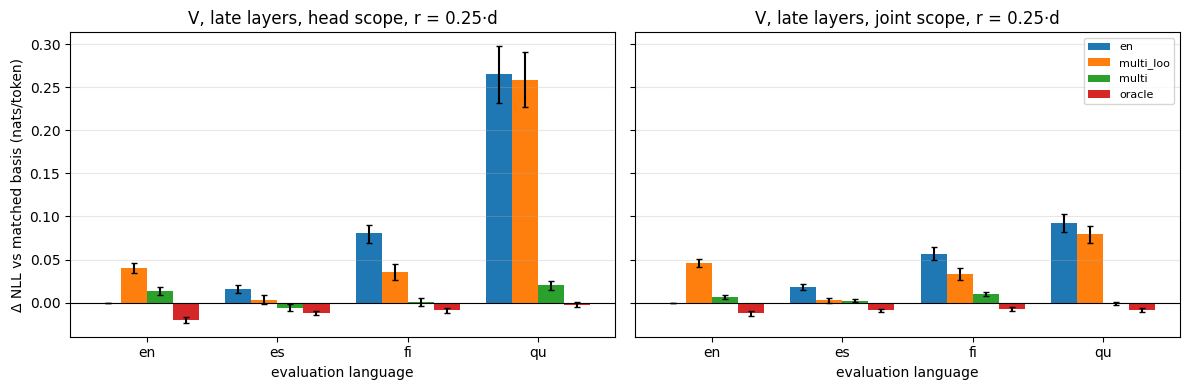

In [11]:
# Fig. 1 — V penalty vs matched basis, by source, with 95% CIs
f0 = RANK_FRACS[0]
show = [s for s in ["en", "multi_loo", "multi", "oracle"]]
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
w = 0.8 / len(show)
for ax, scope in zip(axes, SCOPES):
    x = np.arange(len(LANGS))
    for k, s in enumerate(show):
        q = res[(res.kind == "V") & (res.scope == scope) & (res.rank_frac == f0) & (res.source == s)].set_index("target")
        q = q.reindex(LANGS)
        y = q.delta_nll.values
        err = np.vstack([y - q.ci_low.values, q.ci_high.values - y])
        ax.bar(x + (k - (len(show) - 1) / 2) * w, np.nan_to_num(y), w, yerr=np.nan_to_num(err), capsize=2, label=s)
    ax.axhline(0, color="k", lw=.8); ax.set_xticks(x, LANGS); ax.set_xlabel("evaluation language")
    ax.set_title(f"V, late layers, {scope} scope, r = {f0:g}·d"); ax.grid(axis="y", alpha=.3)
axes[0].set_ylabel("Δ NLL vs matched basis (nats/token)"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "fig1_v_penalty_by_source.png"), dpi=150); plt.show()

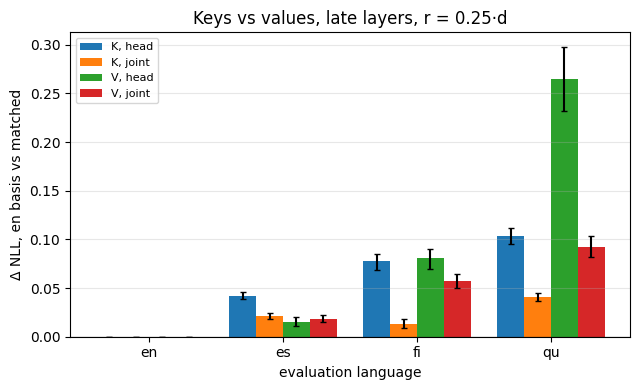

In [12]:
# Fig. 2 — K vs V: penalty of the English basis
fig, ax = plt.subplots(figsize=(6.5, 4))
x = np.arange(len(LANGS)); w = 0.2
for k, (kind, scope) in enumerate(itertools.product(("K", "V"), SCOPES)):
    q = res[(res.kind == kind) & (res.scope == scope) & (res.rank_frac == f0) & (res.source == LANGS[0])].set_index("target").reindex(LANGS)
    y = np.nan_to_num(q.delta_nll.values)
    err = np.nan_to_num(np.vstack([q.delta_nll.values - q.ci_low.values, q.ci_high.values - q.delta_nll.values]))
    ax.bar(x + (k - 1.5) * w, y, w, yerr=err, capsize=2, label=f"{kind}, {scope}")
ax.axhline(0, color="k", lw=.8); ax.set_xticks(x, LANGS); ax.set_xlabel("evaluation language")
ax.set_ylabel(f"Δ NLL, {LANGS[0]} basis vs matched"); ax.set_title(f"Keys vs values, late layers, r = {f0:g}·d")
ax.legend(fontsize=8); ax.grid(axis="y", alpha=.3)
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "fig2_k_vs_v.png"), dpi=150); plt.show()

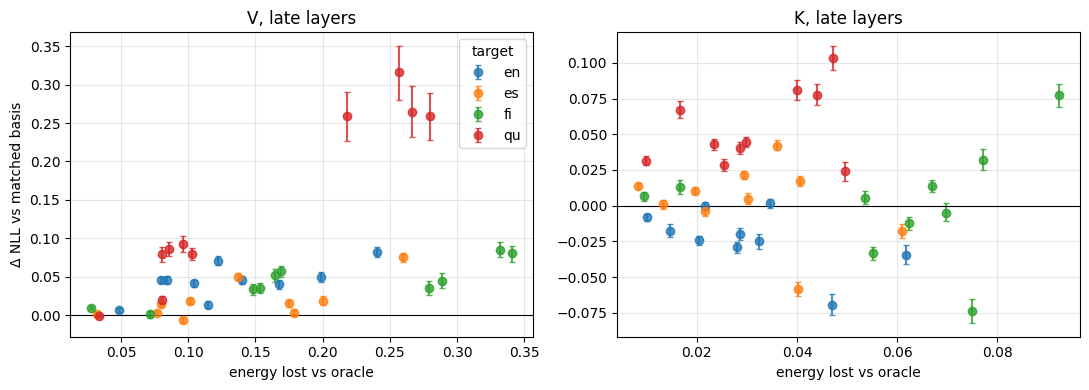

In [13]:
# Fig. 3 — energy lost vs quality lost, coloured by evaluation language
e = energy.groupby(["kind", "rank_frac", "scope", "source", "target"]).efficiency.mean().reset_index()
m = res.merge(e, on=["kind", "rank_frac", "scope", "source", "target"])
m = m[(m.source != m.target) & (m.source != "oracle")]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, kind in zip(axes, ("V", "K")):
    for tgt in LANGS:
        s = m[(m.kind == kind) & (m.target == tgt)]
        ax.errorbar(1 - s.efficiency, s.delta_nll, yerr=[s.delta_nll - s.ci_low, s.ci_high - s.delta_nll],
                    fmt="o", capsize=2, alpha=.8, label=tgt)
    ax.axhline(0, color="k", lw=.8); ax.grid(alpha=.3)
    ax.set_xlabel("energy lost vs oracle"); ax.set_title(f"{kind}, late layers")
axes[0].set_ylabel("Δ NLL vs matched basis"); axes[0].legend(title="target")
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "fig3_energy_vs_quality.png"), dpi=150); plt.show()

In [14]:
import itertools, json, math, os, time
import numpy as np, pandas as pd, torch, matplotlib.pyplot as plt

need = ["model", "data", "gram_calib", "gram_eval", "base_nll", "PROJ", "window_nll", "LATE", "LANGS",
        "N_KV", "HEAD_DIM", "D_KV", "EVAL_BATCH", "SKIP_FIRST_TOKENS", "SEQ_LEN", "SEED", "device"]
missing = [n for n in need if n not in globals()]
assert not missing, f"Run the Week 3 cells (sections 1-3) first. Missing: {missing}"

OUT_DIR = "/kaggle/working/kv_rank_week4" if os.path.isdir("/kaggle/working") else "./kv_rank_week4"
os.makedirs(OUT_DIR, exist_ok=True)

TARGETS = ["qu", "fi"]
MIX_WEIGHTS = (0.0, 0.02, 0.05, 0.10, 0.25, 1.0)   # weight of the target language in the mixture
R_V = 0.25
V_SCOPES = ("head", "joint")
K_RANKS = (0.5, 0.75)
K_SCOPES = ("head",)
N_BOOT = 2000
DRY_RUN = False        # True: run only 3 configs per part, to check timing

def top_basis(G, r):
    lam, U = np.linalg.eigh(G)
    return U[:, ::-1][:, :r]

def blocks(G):
    return [G[h*HEAD_DIM:(h+1)*HEAD_DIM, h*HEAD_DIM:(h+1)*HEAD_DIM] for h in range(N_KV)]

def make_projector(G, scope, f):
    if scope == "head":
        r = max(1, round(f * HEAD_DIM))
        P = np.stack([(lambda U: U @ U.T)(top_basis(B, r)) for B in blocks(G)])
    else:
        r = max(1, round(f * D_KV))
        U = top_basis(G, r); P = U @ U.T
    return torch.tensor(P, dtype=next(model.parameters()).dtype, device=device)

def project_hook(P, scope):
    def fn(mod, inp, out):
        if scope == "head":
            B, T, _ = out.shape
            return torch.einsum("btnd,nde->btne", out.view(B, T, N_KV, HEAD_DIM), P).reshape(B, T, D_KV)
        return out @ P
    return fn

def run_cfg(tgt, kind, grams_by_layer, scope, f):
    hs = [PROJ[kind][l].register_forward_hook(project_hook(make_projector(grams_by_layer[l], scope, f), scope))
          for l in LATE]
    try:
        return window_nll(data[tgt]["eval"], EVAL_BATCH)
    finally:
        for h in hs: h.remove()

rng = np.random.default_rng(SEED)
def paired(a, b):
    d = a - b
    boots = d[rng.integers(0, len(d), size=(N_BOOT, len(d)))].mean(1)
    return d.mean(), np.percentile(boots, 2.5), np.percentile(boots, 97.5)

fmt_tok = lambda n: f"{n * SEQ_LEN / 1000:.0f}k"
print("ok | late layers:", LATE[0], "-", LATE[-1])

ok | late layers: 21 - 27


In [15]:
@torch.no_grad()
def late_v_grams(windows, wanted, batch=5):
    """Per-token-normalised V Gram (late layers), snapshotted after each window budget in `wanted`."""
    acc = {l: torch.zeros(D_KV, D_KV, dtype=torch.float64, device=device) for l in LATE}
    count = [0]
    def mk(l):
        def fn(mod, inp, out):
            x = out[:, SKIP_FIRST_TOKENS:, :].reshape(-1, out.shape[-1]).float()
            acc[l] += (x.T @ x).double()
            if l == LATE[0]:
                count[0] += x.shape[0]
        return fn
    hs = [PROJ["V"][l].register_forward_hook(mk(l)) for l in LATE]
    snaps, done = {}, 0
    try:
        for i in range(0, len(windows), batch):
            ids = windows[i:i + batch].to(device)
            model(input_ids=ids, use_cache=False)
            done += ids.shape[0]
            if done in wanted or done == len(windows):
                snaps[done] = {l: (acc[l] / count[0]).cpu().numpy() for l in LATE}
    finally:
        for h in hs: h.remove()
    return snaps

budgets, snapshots = {}, {}
for t in TARGETS:
    full = len(data[t]["calib"])
    assert full > 40, f"{t}: only {full} calibration windows"
    budgets[t] = sorted({10, 40, full})
    t0 = time.time()
    snapshots[t] = late_v_grams(data[t]["calib"], set(budgets[t]))
    print(t, "snapshots at", [fmt_tok(n) for n in sorted(snapshots[t])], f"({time.time()-t0:.0f}s)")

qu snapshots at ['5k', '20k', '150k'] (47s)
fi snapshots at ['5k', '20k', '150k'] (48s)


In [16]:
other_grams = {t: {l: np.mean([gram_calib[s]["V"][l] for s in LANGS if s != t], axis=0) for l in LATE}
               for t in TARGETS}

def v_grams(tgt, src, w=None, n=None):
    if src == "mix":
        if w == 0:
            return other_grams[tgt]
        return {l: (1 - w) * other_grams[tgt][l] + w * snapshots[tgt][n][l] for l in LATE}
    g = {"matched": gram_calib[tgt], "oracle": gram_eval[tgt], "en": gram_calib["en"]}[src]
    return {l: g["V"][l] for l in LATE}

cfgsA = []
for tgt, scope in itertools.product(TARGETS, V_SCOPES):
    for src in ("matched", "en", "oracle"):
        cfgsA.append((tgt, scope, src, None, None))
    cfgsA.append((tgt, scope, "mix", 0.0, None))
    for w in MIX_WEIGHTS[1:]:
        for n in budgets[tgt]:
            cfgsA.append((tgt, scope, "mix", w, n))
if DRY_RUN: cfgsA = cfgsA[:3]
print(len(cfgsA), "configurations (Part A)")

nllA, t0 = {}, time.time()
for i, (tgt, scope, src, w, n) in enumerate(cfgsA):
    nllA[(tgt, scope, src, w, n)] = run_cfg(tgt, "V", v_grams(tgt, src, w, n), scope, R_V)
    if (i + 1) % 5 == 0 or i + 1 == len(cfgsA):
        el = time.time() - t0
        print(f"{i+1}/{len(cfgsA)}  {el/60:.1f} min elapsed, ~{el/(i+1)*(len(cfgsA)-i-1)/60:.1f} min left")

rows = []
for (tgt, scope, src, w, n), nll in nllA.items():
    ref = nllA.get((tgt, scope, "matched", None, None))
    d = (np.nan,) * 3 if src == "matched" or ref is None else paired(nll, ref)
    rows.append(dict(target=tgt, scope=scope, source=src, w=w, n_windows=n,
                     n_tokens=None if n is None else n * SEQ_LEN,
                     ppl_increase_pct=100 * (math.exp(nll.mean() - base_nll[tgt].mean()) - 1),
                     delta_nll=d[0], ci_low=d[1], ci_high=d[2]))
A = pd.DataFrame(rows)
A.to_csv(os.path.join(OUT_DIR, "mixture_results.csv"), index=False)

print("\nReference bases (delta NLL vs matched basis; 'en' = English basis):")
display(A[A.source.isin(["en", "oracle"])][["target", "scope", "source", "delta_nll", "ci_low", "ci_high"]].round(4))
print("Mixture: delta NLL vs matched basis, columns = amount of target-language text ('-' = none)")
M = A[A.source == "mix"].assign(tok=lambda d: d.n_windows.map(lambda n: "-" if pd.isna(n) else fmt_tok(n)))
display(M.pivot_table(index=["target", "scope", "w"], columns="tok", values="delta_nll").round(3))

76 configurations (Part A)
5/76  1.7 min elapsed, ~24.5 min left
10/76  3.5 min elapsed, ~22.9 min left
15/76  5.2 min elapsed, ~21.2 min left
20/76  7.0 min elapsed, ~19.7 min left
25/76  9.0 min elapsed, ~18.4 min left
30/76  11.0 min elapsed, ~16.8 min left
35/76  12.9 min elapsed, ~15.1 min left
40/76  14.8 min elapsed, ~13.3 min left
45/76  16.5 min elapsed, ~11.4 min left
50/76  18.2 min elapsed, ~9.5 min left
55/76  20.0 min elapsed, ~7.6 min left
60/76  21.9 min elapsed, ~5.8 min left
65/76  23.9 min elapsed, ~4.0 min left
70/76  25.8 min elapsed, ~2.2 min left
75/76  27.8 min elapsed, ~0.4 min left
76/76  28.2 min elapsed, ~0.0 min left

Reference bases (delta NLL vs matched basis; 'en' = English basis):


,target,scope,source,delta_nll,ci_low,ci_high
1,qu,head,en,0.2650,0.2320,0.2986
2,qu,head,oracle,-0.0027,-0.0055,0.0001
20,qu,joint,en,0.0921,0.0817,0.1028
21,qu,joint,oracle,-0.0088,-0.0114,-0.0064
39,fi,head,en,0.0805,0.0707,0.0913
40,fi,head,oracle,-0.0088,-0.0115,-0.0064
58,fi,joint,en,0.0569,0.0492,0.0645
59,fi,joint,oracle,-0.0072,-0.0093,-0.0054


Mixture: delta NLL vs matched basis, columns = amount of target-language text ('-' = none)


tok                    -   150k    20k     5k
target scope w                               
fi     head  0.00  0.035    NaN    NaN    NaN
             0.02    NaN  0.011  0.012  0.011
             0.05    NaN  0.008  0.009  0.006
             0.10    NaN  0.003  0.005  0.001
             0.25    NaN  0.001  0.002 -0.001
             1.00    NaN  0.000  0.004  0.012
       joint 0.00  0.034    NaN    NaN    NaN
             0.02    NaN  0.010  0.011  0.009
             0.05    NaN  0.008  0.010  0.007
             0.10    NaN  0.009  0.010  0.007
             0.25    NaN  0.010  0.012  0.009
             1.00    NaN -0.000  0.002  0.006
qu     head  0.00  0.259    NaN    NaN    NaN
             0.02    NaN  0.174  0.188  0.166
             0.05    NaN  0.117  0.133  0.109
             0.10    NaN  0.065  0.084  0.058
             0.25    NaN  0.020  0.029  0.022
             1.00    NaN  0.000  0.006  0.012
       joint 0.00  0.079    NaN    NaN    NaN
             0.02    NaN  0.017  0.024  0.015
             0.05    NaN  0.004  0.008  0.004
             0.10    NaN  0.001  0.002  0.001
             0.25    NaN -0.001  0.000  0.000
             1.00    NaN  0.000 -0.003 -0.003

In [17]:
multi_K = {l: np.mean([gram_calib[s]["K"][l] for s in LANGS], axis=0) for l in LATE}

def k_grams(tgt, src):
    if src == "multi":
        return multi_K
    g = {"matched": gram_calib[tgt], "oracle": gram_eval[tgt], "en": gram_calib["en"]}[src]
    return {l: g["K"][l] for l in LATE}

cfgsB = [(tgt, f, scope, src)
         for tgt, f, scope in itertools.product(LANGS, K_RANKS, K_SCOPES)
         for src in ("matched", "en", "multi", "oracle") if not (src == "en" and tgt == "en")]
if DRY_RUN: cfgsB = cfgsB[:3]
print(len(cfgsB), "configurations (Part B)")

nllB, t0 = {}, time.time()
for i, (tgt, f, scope, src) in enumerate(cfgsB):
    nllB[(tgt, f, scope, src)] = run_cfg(tgt, "K", k_grams(tgt, src), scope, f)
    if (i + 1) % 5 == 0 or i + 1 == len(cfgsB):
        el = time.time() - t0
        print(f"{i+1}/{len(cfgsB)}  {el/60:.1f} min elapsed, ~{el/(i+1)*(len(cfgsB)-i-1)/60:.1f} min left")

rows = []
for (tgt, f, scope, src), nll in nllB.items():
    ref = nllB.get((tgt, f, scope, "matched"))
    d = (np.nan,) * 3 if src == "matched" or ref is None else paired(nll, ref)
    rows.append(dict(target=tgt, rank_frac=f, scope=scope, source=src,
                     ppl_increase_pct=100 * (math.exp(nll.mean() - base_nll[tgt].mean()) - 1),
                     delta_nll=d[0], ci_low=d[1], ci_high=d[2]))
B = pd.DataFrame(rows)
B.to_csv(os.path.join(OUT_DIR, "k_results.csv"), index=False)

print("K, late layers: perplexity increase over uncompressed (%)")
display(B.pivot_table(index=["rank_frac", "target"], columns="source", values="ppl_increase_pct").round(1))
print("K: delta NLL vs matched basis (negative = the other basis is BETTER than matched)")
display(B.pivot_table(index=["rank_frac", "target"], columns="source", values="delta_nll").round(3))

30 configurations (Part B)
5/30  1.7 min elapsed, ~8.5 min left
10/30  3.4 min elapsed, ~6.9 min left
15/30  5.2 min elapsed, ~5.2 min left
20/30  6.9 min elapsed, ~3.5 min left
25/30  8.7 min elapsed, ~1.7 min left
30/30  10.4 min elapsed, ~0.0 min left
K, late layers: perplexity increase over uncompressed (%)


source               en  matched  multi  oracle
rank_frac target                               
0.50      en        NaN    108.7  110.3   104.4
          es      100.3     95.0  101.9    97.6
          fi      200.6    200.6  209.4   194.2
          qu      104.1     98.8  107.2    99.5
0.75      en        NaN     68.8   72.6    65.7
          es       62.2     62.3   65.1    61.6
          fi      113.4    119.6  117.5   115.7
          qu       60.2     57.3   62.4    55.7

K: delta NLL vs matched basis (negative = the other basis is BETTER than matched)


source               en  multi  oracle
rank_frac target                      
0.50      en        NaN  0.008  -0.021
          es      0.027  0.035   0.013
          fi      0.000  0.029  -0.022
          qu      0.026  0.042   0.003
0.75      en        NaN  0.022  -0.019
          es     -0.000  0.017  -0.004
          fi     -0.029 -0.010  -0.018
          qu      0.019  0.032  -0.010

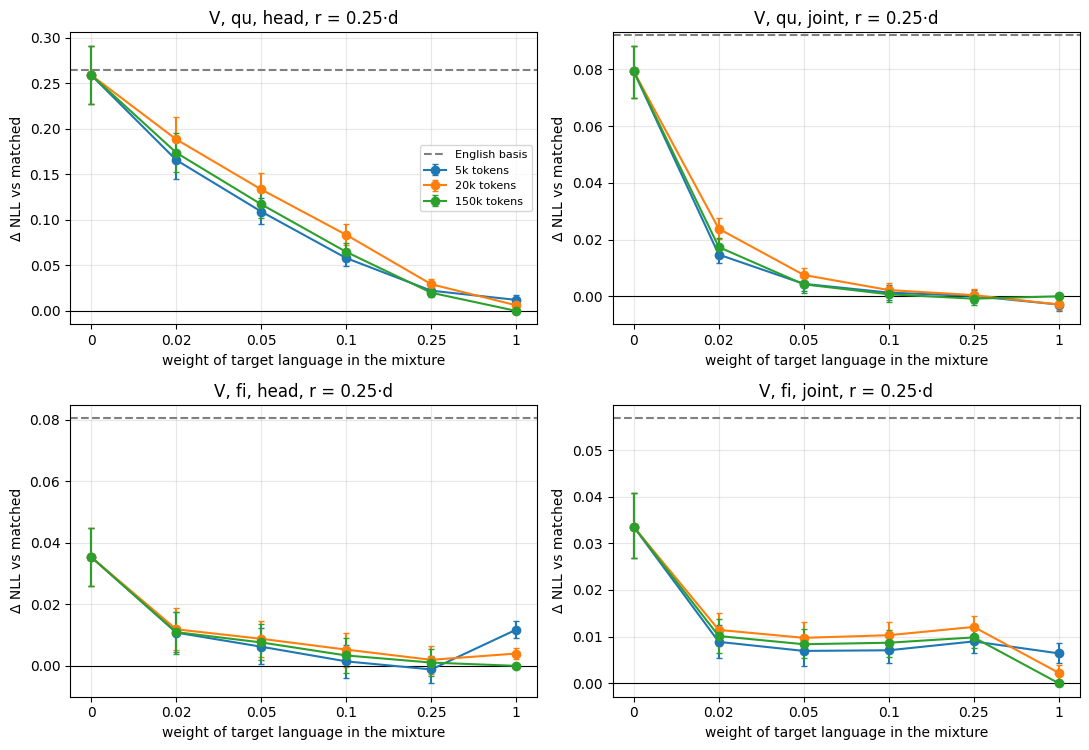

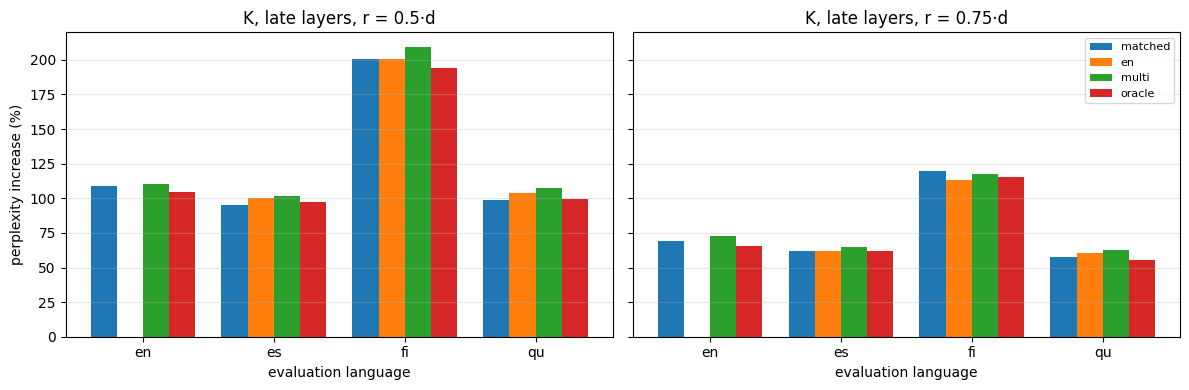

In [18]:
if not DRY_RUN:
    # Fig 1: how much target-language text does the mixture need?
    fig, axes = plt.subplots(len(TARGETS), len(V_SCOPES), figsize=(11, 3.8 * len(TARGETS)), squeeze=False)
    xpos = np.arange(len(MIX_WEIGHTS))
    for i, tgt in enumerate(TARGETS):
        for j, scope in enumerate(V_SCOPES):
            ax = axes[i][j]
            sub = A[(A.target == tgt) & (A.scope == scope)]
            w0 = sub[(sub.source == "mix") & (sub.w == 0.0)].iloc[0]
            for n in budgets[tgt]:
                pts = [w0] + [sub[(sub.source == "mix") & (sub.w == w) & (sub.n_windows == n)].iloc[0]
                              for w in MIX_WEIGHTS[1:]]
                y = np.array([p.delta_nll for p in pts])
                lo = np.array([p.ci_low for p in pts]); hi = np.array([p.ci_high for p in pts])
                ax.errorbar(xpos, y, yerr=[y - lo, hi - y], marker="o", capsize=2, label=f"{fmt_tok(n)} tokens")
            ax.axhline(sub[sub.source == "en"].iloc[0].delta_nll, ls="--", color="gray", label="English basis")
            ax.axhline(0, color="k", lw=.8)
            ax.set_xticks(xpos, [f"{w:g}" for w in MIX_WEIGHTS])
            ax.set_xlabel("weight of target language in the mixture")
            ax.set_ylabel("Δ NLL vs matched"); ax.set_title(f"V, {tgt}, {scope}, r = {R_V:g}·d")
            ax.grid(alpha=.3)
    axes[0][0].legend(fontsize=8)
    plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "fig1_mixture_weight.png"), dpi=150); plt.show()

    # Fig 2: K at milder ranks
    srcs = ["matched", "en", "multi", "oracle"]
    fig, axes = plt.subplots(1, len(K_RANKS), figsize=(6 * len(K_RANKS), 4), sharey=True, squeeze=False)
    for ax, f in zip(axes[0], K_RANKS):
        x = np.arange(len(LANGS)); w = 0.2
        for k, s in enumerate(srcs):
            vals = [B[(B.rank_frac == f) & (B.target == t) & (B.source == s)].ppl_increase_pct.mean() for t in LANGS]
            ax.bar(x + (k - 1.5) * w, vals, w, label=s)
        ax.set_xticks(x, LANGS); ax.set_title(f"K, late layers, r = {f:g}·d"); ax.grid(axis="y", alpha=.3)
        ax.set_xlabel("evaluation language")
    axes[0][0].set_ylabel("perplexity increase (%)"); axes[0][-1].legend(fontsize=8)
    plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "fig2_k_soft_ranks.png"), dpi=150); plt.show()

## 8. What to send back

Upload `ppl_results.csv`, `energy_heldout.csv`, `baseline_ppl.json`, `window_nll.npz` and the
three figures to Drive. If `multi_loo` closes most of the gap, the paper has a practical
recommendation; if it does not, the recommendation is target-language calibration.